# code_178 · Failure time is not a negative class label

**Book:** section 34.1. Restart and run all cells. All imports, helpers and generated inputs are internal. Ordinary execution requires no files, network, credentials or GPU. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_34_GUIDE.md), [execution evidence](../CHAPTER_34_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_178).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, Torch 2.14.1 CPU. Allow two minutes to run and 45–90 minutes to interpret. Original small implementations expose actual updates and controls; they are not benchmark reproductions or field causal conclusions. Target semantics, censoring or exposure, information roles and independent assessment are explicit. Generated records do not establish field performance or intervention validity. Original scoped mechanisms are identified separately from native library models.


In [1]:
import platform,time,json,copy,hashlib,itertools
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
import torch
from torch import nn
START=time.perf_counter();SEED=7578;rng=np.random.default_rng(SEED)
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__,'torch':torch.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
CPU: Darwin arm64 seed: 7578


<a id="censor-aware-survival-models"></a>
 ## Fit likelihoods and risk sets rather than regress censored durations
 Each component is observed from installation; calendar entry is 0,1,2 or 3 and administrative cutoff is calendar year 6. Service age starts at installation, so this is not survivor-recruited delayed entry. Source 480/development 120/final 240 components are independent. Weibull failure time has log relative hazard 0.7 x 0+0.8 x 1². Source-only Cox uses those declared two features. An original 30-tree forest uses bootstrap samples, one randomly offered raw feature per node, five candidate quantiles, logrank split statistics, minimum 20 records per daughter, depth 4 and Nelson–Aalen leaf cumulative hazards averaged across trees. It is a small survival forest mechanism, not a full library or original benchmark reproduction. A 2→16→6 neural hazard head fits 500 Adam steps using six annual intervals; administrative censoring is exactly at interval endpoints. Observed events contribute an event-bin likelihood and prior survived bins; censored records contribute only survived bins. All settings are fixed; development is diagnostic only.


,model,horizon,IPCW_Brier,weighted_dynamic_AUC,oracle_full_time_Brier_for_audit,censor_survival_left
0,KM,2.0,0.200486,0.500000,0.200486,1.000000
1,KM,4.0,0.234059,0.500000,0.243839,0.763485
2,KM,5.0,0.188763,0.500000,0.212121,0.501560
3,Cox,2.0,0.183847,0.698363,0.183847,1.000000
4,Cox,4.0,0.215428,0.668544,0.220066,0.763485
5,Cox,5.0,0.174703,0.685012,0.181348,0.501560
6,Forest,2.0,0.185644,0.676332,0.185644,1.000000
7,Forest,4.0,0.214501,0.662592,0.219370,0.763485
8,Forest,5.0,0.172086,0.694006,0.179220,0.501560
9,Neural,2.0,0.185998,0.679206,0.185998,1.000000


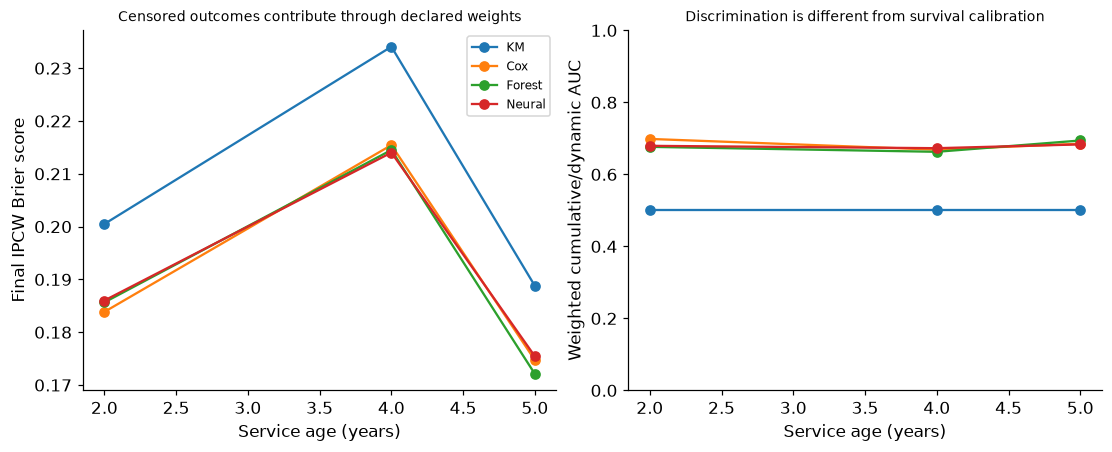

In [2]:
from scipy.optimize import minimize
from sklearn.metrics import roc_auc_score
def cohort(n,gr):
    x=gr.uniform(-1,1,(n,2));entry=gr.integers(0,4,n);censor=6-entry;failure=5*(-np.log(gr.uniform(1e-8,1,n))/np.exp(.7*x[:,0]+.8*x[:,1]**2))**(1/1.4);return x,np.minimum(failure,censor),failure<=censor,entry,failure
sx,st,sd,se,sf=cohort(480,rng);dx,dt,dd,de,df=cohort(120,rng);fx,ft,fd,fe,ff=cohort(240,rng);grid=np.arange(1.,7.);CX=np.column_stack([sx[:,0],sx[:,1]**2]);risk=torch.tensor(st[None,:]>=st[:,None]);CXt=torch.tensor(CX);evt=torch.tensor(sd)
def cox_objective(b):
    z=torch.tensor(b,requires_grad=True);eta=CXt@z;den=torch.logsumexp(eta[None,:].expand(480,-1).masked_fill(~risk,-torch.inf),1);loss=-(eta[evt]-den[evt]).mean()+.001*z.square().sum();loss.backward();return float(loss.detach()),z.grad.numpy()
fitted=minimize(cox_objective,np.zeros(2),jac=True,method='BFGS',options={'gtol':1e-7,'maxiter':200});beta=fitted.x;event_times=np.unique(st[sd]);haz_inc=np.array([np.sum(sd&(st==t))/np.exp(CX[st>=t]@beta).sum() for t in event_times]);base=np.array([haz_inc[event_times<=t].sum() for t in grid])
def cox_survival(x):return np.exp(-np.exp(np.column_stack([x[:,0],x[:,1]**2])@beta)[:,None]*base)
def km(t,d,at,left=False):
    et=np.unique(t[d]);rr=np.array([np.sum(t>=z) for z in et]);death=np.array([np.sum((t==z)&d) for z in et]);out=[]
    for z in np.asarray(at):out.append(float(np.prod(1-death[et<z if left else et<=z]/rr[et<z if left else et<=z])))
    return np.array(out)
def leaf(ids):return np.array([np.sum([np.sum(sd[ids]&(st[ids]==z))/np.sum(st[ids]>=z) for z in np.unique(st[ids][sd[ids]]) if z<=t]) for t in grid])
forest_rng=np.random.default_rng(SEED+10)
def grow(ids,depth=0):
    if depth>=4 or len(ids)<40 or sd[ids].sum()<6:return ('leaf',leaf(ids))
    times=np.unique(st[ids][sd[ids]]);R=(st[ids,None]>=times[None,:]).astype(float);D=((st[ids,None]==times[None,:])&sd[ids,None]).astype(float);yr=R.sum(0);dr=D.sum(0);best=None;feature=int(forest_rng.integers(2))
    for cut in np.quantile(sx[ids,feature],[.2,.35,.5,.65,.8]):
        left=sx[ids,feature]<=cut
        if min(left.sum(),(~left).sum())<20:continue
        yl=left.astype(float)@R;dl=left.astype(float)@D;fraction=yl/yr;variance=np.sum(fraction*(1-fraction)*dr*np.divide(yr-dr,yr-1,out=np.zeros_like(yr),where=yr>1));score=float((dl-fraction*dr).sum()**2/max(variance,1e-12))
        if best is None or score>best[0]:best=(score,float(cut),left)
    if best is None:return ('leaf',leaf(ids))
    _,cut,left=best;return ('node',feature,cut,grow(ids[left],depth+1),grow(ids[~left],depth+1))
forest=[grow(forest_rng.integers(0,480,480)) for _ in range(30)]
def tree_hazard(node,x):
    if node[0]=='leaf':return node[1]
    return tree_hazard(node[3] if x[node[1]]<=node[2] else node[4],x)
def forest_survival(x):return np.exp(-np.mean([[tree_hazard(tree,row) for row in x] for tree in forest],axis=0))
net=nn.Sequential(nn.Linear(2,16),nn.Tanh(),nn.Linear(16,6));opt=torch.optim.Adam(net.parameters(),lr=.01);X=torch.tensor(sx);survived=torch.tensor(st[:,None]>=grid[None,:]);event_bin=np.minimum(st.astype(int),5);event_mask=torch.zeros((480,6));event_mask[torch.arange(480)[evt],torch.tensor(event_bin)[evt]]=1.
for step in range(500):
    logits=net(X);loss=-(nn.functional.logsigmoid(-logits)*survived+nn.functional.logsigmoid(logits)*event_mask).sum()/480;opt.zero_grad();loss.backward();opt.step()
def neural_survival(x):
    with torch.no_grad():return torch.cumprod(torch.sigmoid(-net(torch.tensor(x))),1).numpy()
def metrics(x,t,d,latent):
    predictions={'KM':np.repeat(km(st,sd,grid)[None,:],len(x),axis=0),'Cox':cox_survival(x),'Forest':forest_survival(x),'Neural':neural_survival(x)};rows=[]
    for name,S in predictions.items():
        assert np.all(np.diff(S,axis=1)<=1e-10) and np.all((S>=0)&(S<=1))
        for horizon in [2.,4.,5.]:
            surv=S[:,int(horizon)-1];event=d&(t<=horizon);alive=t>=horizon;Gevent=km(st,~sd,t,left=True);Gtime=float(km(st,~sd,[horizon],left=True)[0]);ipcw=np.mean(event*surv**2/np.maximum(Gevent,1e-8)+alive*(1-surv)**2/Gtime);known=event|alive;label=event[known].astype(int);weights=np.where(event[known],1/np.maximum(Gevent[known],1e-8),1/Gtime);auc=roc_auc_score(label,1-surv[known],sample_weight=weights);rows.append({'model':name,'horizon':horizon,'IPCW_Brier':float(ipcw),'weighted_dynamic_AUC':float(auc),'oracle_full_time_Brier_for_audit':float(np.mean((surv-(latent>horizon))**2)),'censor_survival_left':Gtime})
    return rows,predictions
rows,predictions=metrics(fx,ft,fd,ff);dev_rows,_=metrics(dx,dt,dd,df);assert np.isfinite(beta).all() and np.linalg.norm(fitted.jac)<1e-4 and len(forest)==30;assert np.all(st<=6-se) and np.all(st>0)
RESULTS.update(source_components=480,development_components=120,final_components=240,source_events=int(sd.sum()),source_censored=int((~sd).sum()),cox_coefficients=beta.tolist(),cox_optimizer_success=bool(fitted.success),cox_gradient_norm=float(np.linalg.norm(fitted.jac)),forest_trees=30,forest_max_depth=4,forest_min_daughter=20,neural_updates=500,neural_annual_intervals=6,final_metrics=rows,development_metrics=dev_rows,development_used_for_selection=False,final_latent_failure_times_used_for_fitting=False)
display(pd.DataFrame(rows));fig,axes=plt.subplots(1,2,figsize=(10,4))
for name in predictions:
    rr=[r for r in rows if r['model']==name];axes[0].plot([r['horizon'] for r in rr],[r['IPCW_Brier'] for r in rr],marker='o',label=name);axes[1].plot([r['horizon'] for r in rr],[r['weighted_dynamic_AUC'] for r in rr],marker='o',label=name)
axes[0].set(xlabel='Service age (years)',ylabel='Final IPCW Brier score',title='Censored outcomes contribute through declared weights');axes[1].set(xlabel='Service age (years)',ylabel='Weighted cumulative/dynamic AUC',ylim=(0,1),title='Discrimination is different from survival calibration');axes[0].legend(fontsize=8);plt.show()


<a id="competing-events-are-not-independent-missingness"></a>
 ## Estimate failure incidence when retirement prevents its occurrence
 A separate 1,200-component cohort has failure rate 0.14 and retirement rate 0.10, with independent administrative censoring. The first event is observed. A cumulative-incidence estimator increments failure probability by prior all-event survival×failure count/risk set. It accounts for retirement removing probability mass. In contrast,1−KMthat censors retirement estimates a different net-risk quantity under additional assumptions. The analytic cumulative incidence 0.14/0.24×(1−exp(−0.24 t))is simulator-only audit truth. It does not select a curve or supply labels to any fitted survival model.


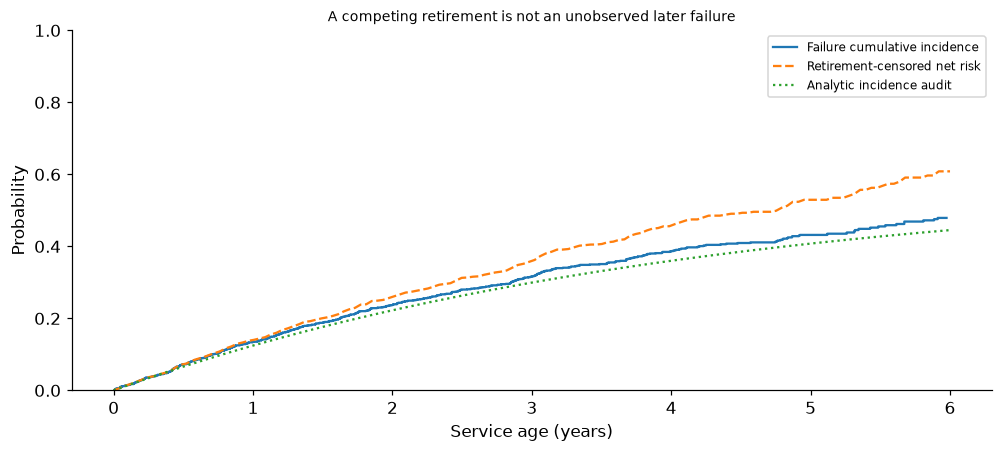

In [3]:
n=1200;entry=rng.integers(0,4,n);tf=rng.exponential(1/.14,n);tr=rng.exponential(1/.10,n);cut=6-entry;time_obs=np.minimum(np.minimum(tf,tr),cut);kind=np.where((tf<=tr)&(tf<=cut),1,np.where((tr<tf)&(tr<=cut),2,0));times=np.unique(time_obs[kind>0]);S=1.;f1=0.;f2=0.;trajectory=[]
for t in times:
    risk_count=np.sum(time_obs>=t);d1=np.sum((time_obs==t)&(kind==1));d2=np.sum((time_obs==t)&(kind==2));f1+=S*d1/risk_count;f2+=S*d2/risk_count;S*=1-(d1+d2)/risk_count;trajectory.append((t,f1,f2,S))
trajectory=np.array(trajectory);np.testing.assert_allclose(trajectory[:,1:].sum(1),1.,atol=1e-12);at=5.;ii=np.searchsorted(trajectory[:,0],at,side='right')-1;actual=float(trajectory[ii,1]);net_risk=float(1-km(time_obs,kind==1,[at])[0]);analytic=.14/.24*(1-np.exp(-.24*at));assert np.all(np.diff(trajectory[:,1])>=-1e-12)
RESULTS.update(competing_components=n,competing_counts={str(i):int(np.sum(kind==i)) for i in [0,1,2]},failure_incidence_age5=actual,retirement_censored_net_risk_age5=net_risk,analytic_failure_incidence_age5=float(analytic))
fig,ax=plt.subplots(figsize=(9,4));tt=np.linspace(0,6,150);ax.step(trajectory[:,0],trajectory[:,1],where='post',label='Failure cumulative incidence');ax.plot(tt,1-km(time_obs,kind==1,tt),'--',label='Retirement-censored net risk');ax.plot(tt,.14/.24*(1-np.exp(-.24*tt)),':',label='Analytic incidence audit');ax.set(xlabel='Service age (years)',ylabel='Probability',ylim=(0,1),title='A competing retirement is not an unobserved later failure');ax.legend(fontsize=8);plt.show()


<a id="calendar-entry-and-service-age"></a>
 ## Calendar entry and service-age risk sets use different clocks
 After the competing-event calculation above, plot the first two failures, first two administratively censored records and first two retirements from that separate 1,200-component cohort, explicitly selected to illustrate endpoint types. Each horizontal interval begins at its installation calendar year. Censored observations stop at the administrative cutoff, not at a known future failure. All model risk sets use service age, with every component observed from service age zero. At age 3 the displayed competing-event cohort risk set contains every component still under observation and free of either event at 3, regardless of calendar installation year. A genuinely survivor-recruited cohort with delayed service-age entry would require left-truncation risk sets; this example does not claim to fit them.


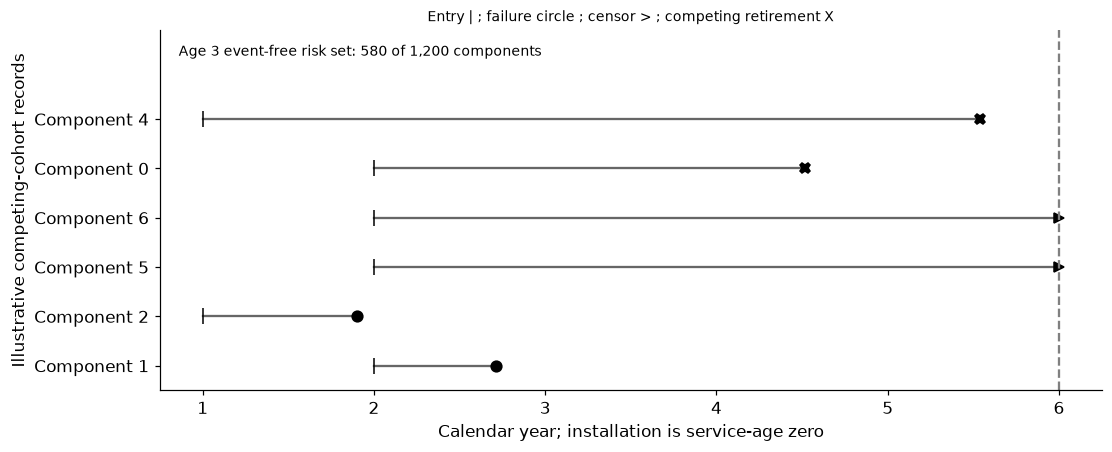

In [4]:
ids=np.r_[np.flatnonzero(kind==1)[:2],np.flatnonzero(kind==0)[:2],np.flatnonzero(kind==2)[:2]];risk_age3=int(np.sum(time_obs>=3));assert len(ids)==6 and risk_age3>0
RESULTS.update(calendar_cutoff=6,illustration_competing_cohort_ids=ids.tolist(),competing_service_age3_risk_set=risk_age3,components_observed_from_installation=True,left_truncation_claimed=False)
fig,ax=plt.subplots(figsize=(10,4))
for row,i in enumerate(ids):ax.plot([entry[i],entry[i]+time_obs[i]],[row,row],color='.4');ax.plot(entry[i],row,'|',color='black',markersize=10);ax.plot(entry[i]+time_obs[i],row,{1:'o',0:'>',2:'X'}[int(kind[i])],color='black',markersize=7)
ax.axvline(6,color='.5',linestyle='--');ax.set_ylim(-.5,6.8);ax.set(yticks=range(6),yticklabels=[f'Component {i}' for i in ids],xlabel='Calendar year; installation is service-age zero',ylabel='Illustrative competing-cohort records',title='Entry | ; failure circle ; censor > ; competing retirement X');ax.text(.02,.96,f'Age 3 event-free risk set: {risk_age3} of 1,200 components',transform=ax.transAxes,va='top',fontsize=9);plt.show()


In [5]:
summary={'example_id':'code_178','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual Cox partial-likelihood optimization with Breslow baseline', 'original bootstrap logrank-split survival forest with Nelson Aalen leaf hazards', 'actual discrete neural hazard likelihood with endpoint censoring', 'independent IPCW Brier and cumulative dynamic AUC assessment', 'entry origins and risk sets plus actual competing-event cumulative incidence'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual Cox partial-likelihood optimization with Breslow baseline", "original bootstrap logrank-split survival forest with Nelson Aalen leaf hazards", "actual discrete neural hazard likelihood with endpoint censoring", "independent IPCW Brier and cumulative dynamic AUC assessment", "entry origins and risk sets plus actual competing-event cumulative incidence"], "elapsed_seconds": 0.867, "example_id": "code_178", "hardware": "Darwin arm64 CPU", "results": {"analytic_failure_incidence_age5": 0.4076367097178821, "calendar_cutoff": 6, "competing_components": 1200, "competing_counts": {"0": 411, "1": 482, "2": 307}, "competing_service_age3_risk_set": 580, "components_observed_from_installation": true, "cox_coefficients": [0.7255885132463814, 0.8166688768117845], "cox_gradient_norm": 4.9316733032622444e-11, "cox_optimizer_success": true, "development_components": 120, "development_metrics": [{"IPCW_Brier": 0.22604166666666672, "censor_surviva